# Olist E-commerce — Key Visualizations

Eight charts that tell the project's business story: **growth → what sells → who buys again → where the customer experience breaks → who sells**.

Data: `data/cleaned/` (run `python python/data_cleaning.py` first). Charts are saved to `images/` and used in the README.

Metric definitions: **GMV** = sum of item `price` (product sales value, excludes freight); **late** = delivered after the estimated date, evaluated only for delivered orders with both dates. Customers are identified by `customer_unique_id`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

DATA = Path("../data/cleaned")
IMG = Path("../images")
IMG.mkdir(exist_ok=True)

# Palette: one accent for the focus series, orange for the contrast case, grey for context
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b8b6ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "text.parse_math": False, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
millions = mtick.FuncFormatter(lambda x, _: f"R${x / 1e6:.1f}M")
thousands = mtick.FuncFormatter(lambda x, _: f"R${x / 1e3:.0f}K")

def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, color=MUTED, fontsize=9.5, va="bottom")

orders = pd.read_csv(DATA / "orders_clean.csv", parse_dates=["order_purchase_timestamp"])
items = pd.read_csv(DATA / "order_items_clean.csv")
products = pd.read_csv(DATA / "products_clean.csv")
segments = pd.read_csv(DATA / "customer_segments.csv")
items = items.merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
items = items.rename(columns={"product_category_name_english": "category"})

## 1–2. Growth: monthly GMV and orders
Trend window is **Jan-2017 to Aug-2018**. 2016 has only ~300 orders (none in Nov-2016) and Sep/Oct-2018 contain almost only canceled orders, so plotting them would create misleading near-zero months. GMV and orders are shown as two charts rather than a dual axis.

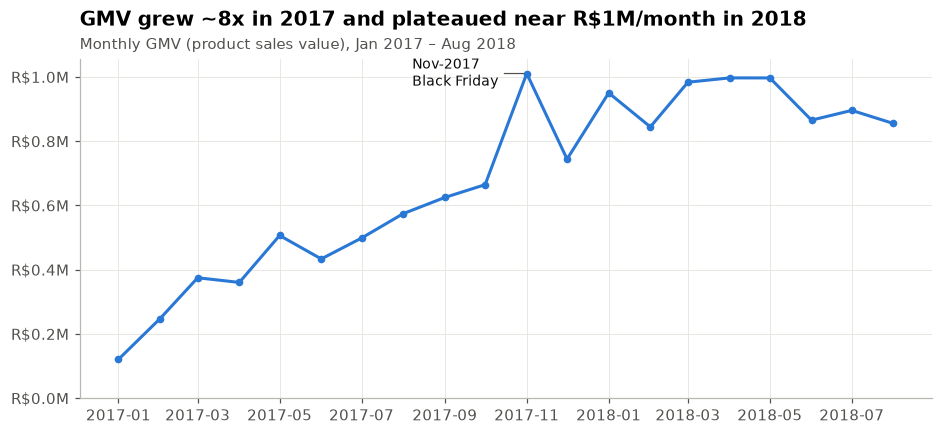

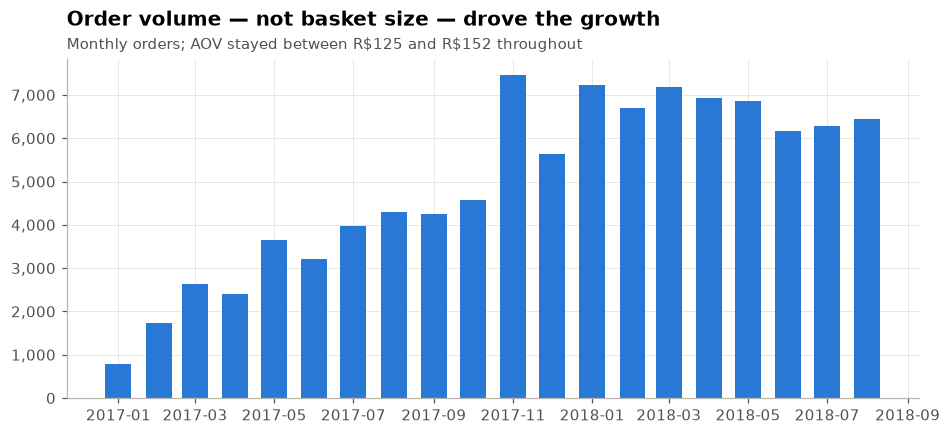

In [2]:
monthly = (orders[orders["items_count"] > 0]
           .groupby("purchase_month")
           .agg(orders=("order_id", "nunique"), gmv=("product_value", "sum"))
           .loc["2017-01":"2018-08"])
monthly.index = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly["gmv"], color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_formatter(millions)
ax.set_ylim(0)
ax.set_title("GMV grew ~8x in 2017 and plateaued near R$1M/month in 2018", pad=22)
subtitle(ax, "Monthly GMV (product sales value), Jan 2017 – Aug 2018")
peak = monthly["gmv"].idxmax()
ax.annotate("Nov-2017\nBlack Friday", (peak, monthly.loc[peak, "gmv"]), xytext=(-75, 0),
            textcoords="offset points", color=INK, fontsize=9, va="center",
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
fig.savefig(IMG / "01_monthly_gmv.png"); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly["orders"], width=20, color=BLUE)
ax.set_title("Order volume — not basket size — drove the growth", pad=22)
subtitle(ax, f"Monthly orders; AOV stayed between R${(monthly.gmv / monthly.orders).min():.0f} "
             f"and R${(monthly.gmv / monthly.orders).max():.0f} throughout")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
fig.savefig(IMG / "02_monthly_orders.png"); plt.show()

## 3–4. What sells: categories by GMV and by units
The two rankings differ: some categories win on volume at low prices, others on high average price.

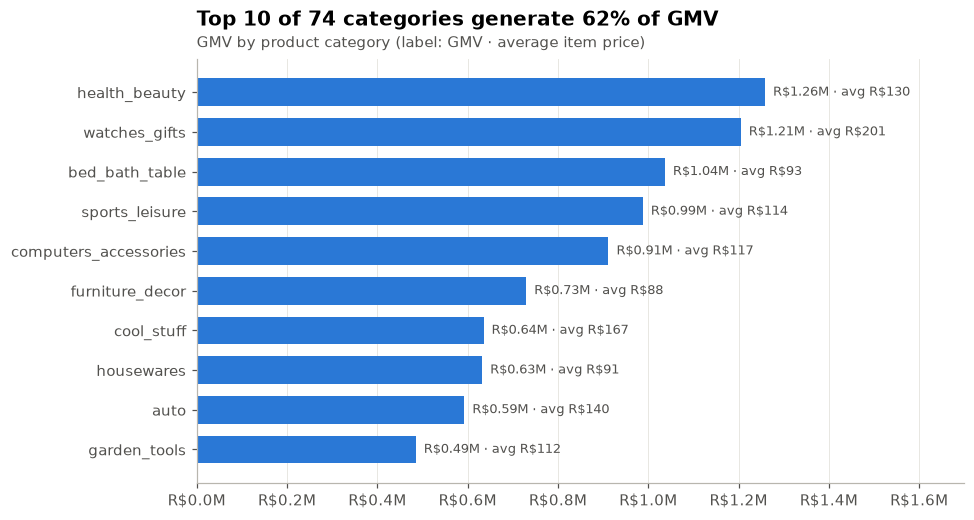

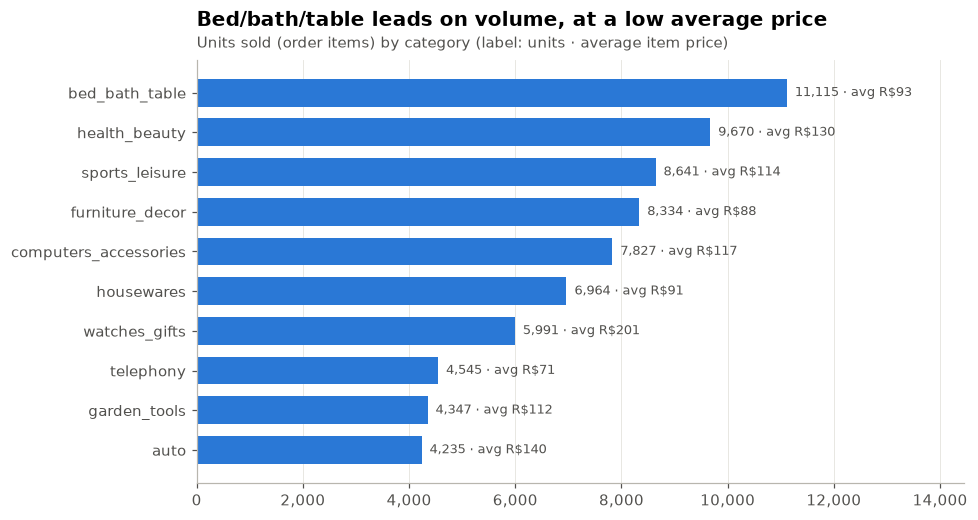

In [3]:
cat = (items.groupby("category")
       .agg(gmv=("price", "sum"), units=("order_item_id", "count"), avg_price=("price", "mean")))
share_top10 = cat["gmv"].nlargest(10).sum() / cat["gmv"].sum()

top_gmv = cat.nlargest(10, "gmv").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_gmv.index, top_gmv["gmv"], color=BLUE, height=0.7)
for y, (v, p) in enumerate(zip(top_gmv["gmv"], top_gmv["avg_price"])):
    ax.text(v, y, f"  R${v / 1e6:.2f}M · avg R${p:.0f}", va="center", fontsize=8.5, color=MUTED)
ax.xaxis.set_major_formatter(millions); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top_gmv["gmv"].max() * 1.35)
ax.set_title(f"Top 10 of {len(cat)} categories generate {share_top10:.0%} of GMV", pad=22)
subtitle(ax, "GMV by product category (label: GMV · average item price)")
fig.savefig(IMG / "03_top_categories_gmv.png"); plt.show()

top_units = cat.nlargest(10, "units").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_units.index, top_units["units"], color=BLUE, height=0.7)
for y, (u, p) in enumerate(zip(top_units["units"], top_units["avg_price"])):
    ax.text(u, y, f"  {u:,} · avg R${p:.0f}", va="center", fontsize=8.5, color=MUTED)
ax.grid(axis="y", visible=False); ax.set_xlim(0, top_units["units"].max() * 1.3)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Bed/bath/table leads on volume, at a low average price", pad=22)
subtitle(ax, "Units sold (order items) by category (label: units · average item price)")
fig.savefig(IMG / "04_top_categories_units.png"); plt.show()

## 5. Who buys again: one-time vs repeat customers
Based on `customer_unique_id` (a `customer_id` is created per order, so it would show zero repeat customers).

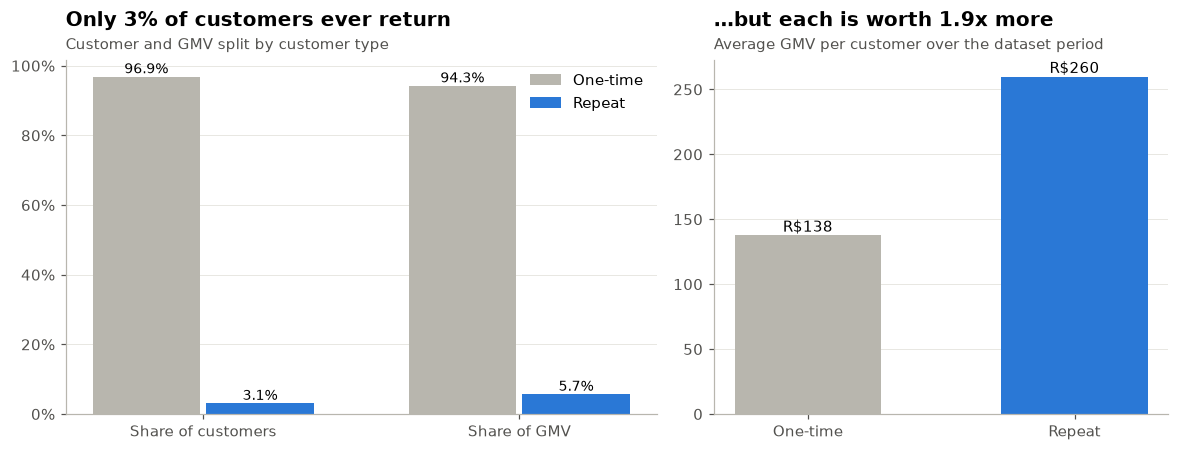

order_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1


In [4]:
seg = segments.groupby("customer_type").agg(customers=("customer_unique_id", "count"),
                                            gmv=("product_value", "sum"),
                                            avg_gmv=("product_value", "mean"))
seg = seg.loc[["one_time", "repeat"]]
seg.index = ["One-time", "Repeat"]
share = pd.DataFrame({"Share of customers": seg["customers"] / seg["customers"].sum(),
                      "Share of GMV": seg["gmv"] / seg["gmv"].sum()})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
x = range(len(share.columns))
ax1.bar([i - 0.18 for i in x], share.loc["One-time"], 0.34, color=GREY, label="One-time")
ax1.bar([i + 0.18 for i in x], share.loc["Repeat"], 0.34, color=BLUE, label="Repeat")
for i, col in enumerate(share.columns):
    for dx, ct in [(-0.18, "One-time"), (0.18, "Repeat")]:
        ax1.text(i + dx, share.loc[ct, col], f"{share.loc[ct, col]:.1%}", ha="center", va="bottom", fontsize=9)
ax1.set_xticks(list(x), share.columns); ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax1.legend(frameon=False); ax1.grid(axis="x", visible=False)
ax1.set_title("Only 3% of customers ever return", pad=22)
subtitle(ax1, "Customer and GMV split by customer type")

ax2.bar(seg.index, seg["avg_gmv"], color=[GREY, BLUE], width=0.55)
for i, v in enumerate(seg["avg_gmv"]):
    ax2.text(i, v, f"R${v:,.0f}", ha="center", va="bottom", fontsize=10)
ax2.grid(axis="x", visible=False)
ratio = seg.loc["Repeat", "avg_gmv"] / seg.loc["One-time", "avg_gmv"]
ax2.set_title(f"…but each is worth {ratio:.1f}x more", pad=22)
subtitle(ax2, "Average GMV per customer over the dataset period")
fig.tight_layout(); fig.savefig(IMG / "05_customer_retention.png"); plt.show()

print(segments["order_count"].value_counts().sort_index().rename("customers").to_string())

## 6. Order outcomes: status distribution
97% of orders are delivered; the chart focuses on where the other 3% sit.

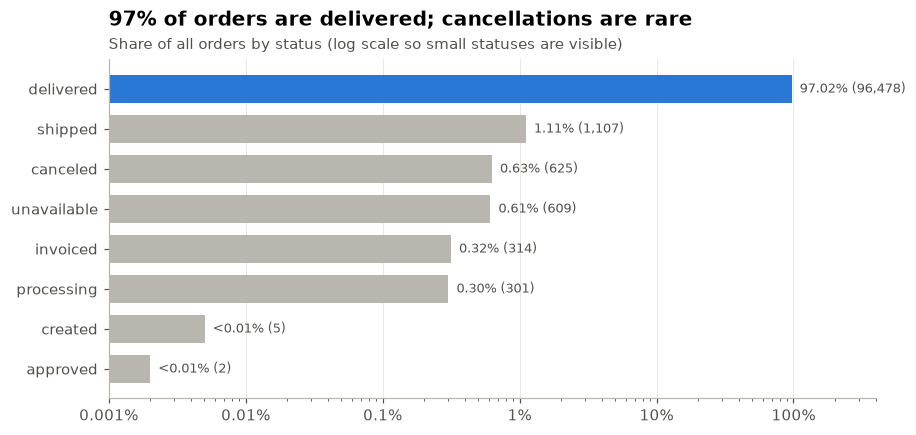

In [5]:
status = orders["order_status"].value_counts()
share = status / status.sum()
fig, ax = plt.subplots(figsize=(9, 4))
s = share.iloc[::-1]
ax.barh(s.index, s.values, color=[BLUE if k == "delivered" else GREY for k in s.index], height=0.7)
for y, (k, v) in enumerate(s.items()):
    pct = f"{v:.2%}" if v >= 0.0001 else "<0.01%"
    ax.text(v, y, f"  {pct} ({status[k]:,})", va="center", fontsize=8.5, color=MUTED)
ax.set_xscale("log"); ax.set_xlim(1e-5, 4)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x * 100:g}%")); ax.grid(axis="y", visible=False)
ax.set_title(f"{share['delivered']:.0%} of orders are delivered; cancellations are rare", pad=22)
subtitle(ax, "Share of all orders by status (log scale so small statuses are visible)")
fig.savefig(IMG / "06_order_status.png"); plt.show()

## 7. Where the experience breaks: delivery timeliness vs review score
Only delivered orders with both a delivery and an estimated date are evaluated. This shows an **association**, not proof that lateness causes low ratings.

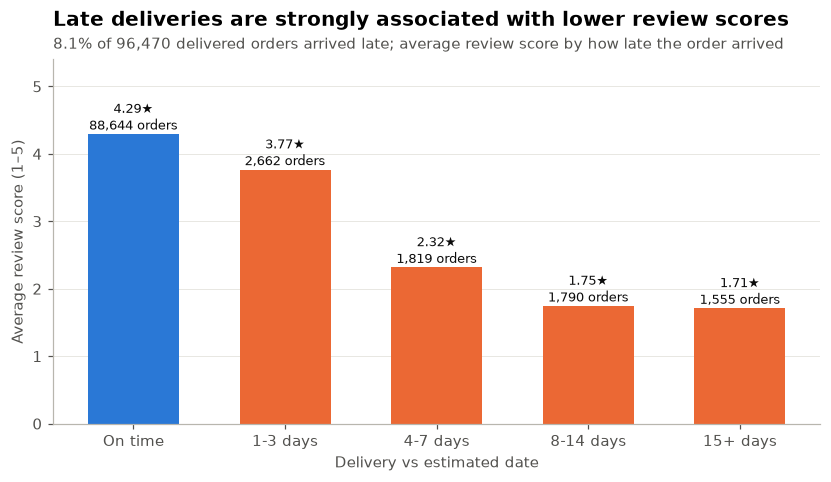

In [6]:
d = orders[orders["delivery_status"].isin(["on_time", "late"])].copy()
d["days_late"] = (pd.to_datetime(d["order_delivered_customer_date"])
                  - pd.to_datetime(d["order_estimated_delivery_date"])).dt.total_seconds() / 86400
labels = ["1-3 days", "4-7 days", "8-14 days", "15+ days"]
d["bucket"] = pd.cut(d["days_late"], [-1, 3, 7, 14, 10_000], labels=labels).astype(str)
d.loc[d["is_late"] == 0, "bucket"] = "On time"
order_ = ["On time"] + labels
by = d.groupby("bucket").agg(orders=("order_id", "count"), review=("review_score", "mean")).loc[order_]
late_rate = d["is_late"].mean()

fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(by.index, by["review"], color=[BLUE] + [ORANGE] * 4, width=0.6)
for i, (r, n) in enumerate(zip(by["review"], by["orders"])):
    ax.text(i, r, f"{r:.2f}★\n{n:,} orders", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_ylim(0, 5.4); ax.set_ylabel("Average review score (1–5)"); ax.grid(axis="x", visible=False)
ax.set_xlabel("Delivery vs estimated date")
ax.set_title("Late deliveries are strongly associated with lower review scores", pad=22)
subtitle(ax, f"{late_rate:.1%} of {len(d):,} delivered orders arrived late; "
             "average review score by how late the order arrived")
fig.savefig(IMG / "07_delivery_vs_reviews.png"); plt.show()

## 8. Who sells: seller concentration
Cumulative share of GMV when sellers are ranked from largest to smallest.

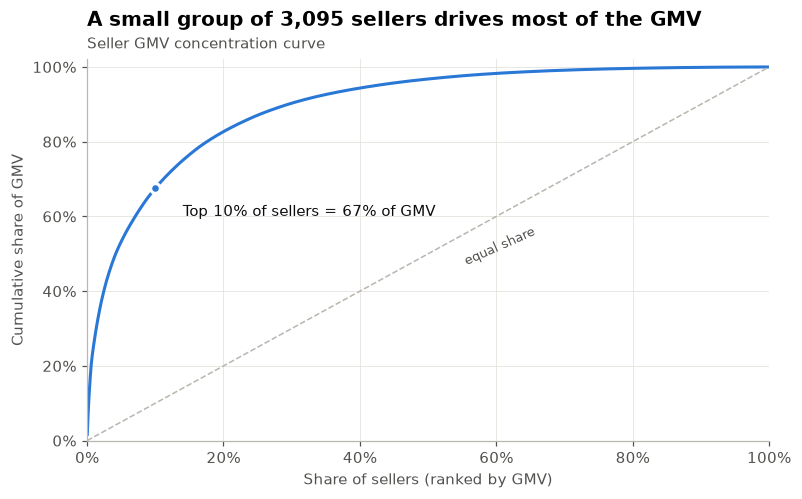

In [7]:
seller_gmv = items.groupby("seller_id")["price"].sum().sort_values(ascending=False)
cum = seller_gmv.cumsum() / seller_gmv.sum()
pct_sellers = (pd.Series(range(1, len(cum) + 1)) / len(cum)).values
top10 = cum.iloc[int(len(cum) * 0.1) - 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pct_sellers, cum.values, color=BLUE, lw=2)
ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--")
ax.text(0.55, 0.47, "equal share", color=MUTED, fontsize=8.5, rotation=24)
ax.scatter([0.1], [top10], color=BLUE, s=40, zorder=3, edgecolor="white", linewidth=2)
ax.annotate(f"Top 10% of sellers = {top10:.0%} of GMV", (0.1, top10), xytext=(18, -18),
            textcoords="offset points", fontsize=9.5, color=INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Share of sellers (ranked by GMV)"); ax.set_ylabel("Cumulative share of GMV")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title(f"A small group of {len(cum):,} sellers drives most of the GMV", pad=22)
subtitle(ax, "Seller GMV concentration curve")
fig.savefig(IMG / "08_seller_concentration.png"); plt.show()

## Takeaways
1. **Growth came from volume**: GMV rose ~137% (Jan–Aug 2018 vs 2017) with a flat AOV (~R$125–153).
2. **Category concentration**: 10 of 74 categories = 62% of GMV; high-volume and high-price categories differ.
3. **Retention is the biggest gap**: 3.1% of customers return, but they are worth ~1.9x more each.
4. **Delivery reliability**: 8.1% of delivered orders were late; late orders average 2.57★ vs 4.29★ on time, and scores fall the later the order is.
5. **Seller concentration**: the top 10% of sellers produce ~2/3 of GMV, so seller quality management has outsized impact.